<a href="https://colab.research.google.com/github/asteriaji/MSSP6070/blob/main/WeeklyModules/Week07/Jiangyu_Ji_PARTICIPATION_ACTIVITY_Week_7_Export_a_bar_chart_from_a_data_frame_to_a_PDF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.formula.api as sm
import statsmodels.api as se
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools
import os
import subprocess
from pathlib import Path

pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

owner = 'asteriaji'
repository = 'MSSP6070'
repo_url = f'https://github.com/{owner}/{repository}.git'
repo_path = Path('/content') / repository

if not repo_path.exists():
    subprocess.run(
        ['git', 'clone', repo_url, str(repo_path)],
        check=True
    )
else:
    print("Repository already exists. Using the existing copy.")

os.chdir(repo_path)

print("Current directory:", os.getcwd())

print("Files in repository:")
for item in sorted(repo_path.rglob('*')):
    if item.is_file() and '.git' not in item.parts:
        print(item.relative_to(repo_path))

Current directory: /content/MSSP6070
Files in repository:
Adding_File_Structure.py
Assignments/.gitkeep
Assignments/Assignment 1/Corrected_Version_Jiangyu_Ji_MSSP_6070_Assignment_1.ipynb
Assignments/Assignment 1/Jiangyu_Ji_MSSP_6070_Assignment_1_260930.ipynb
WeeklyModules/.gitkeep
WeeklyModules/Week01/.gitkeep
WeeklyModules/Week01/1_introducing_matplotlib_(1).ipynb
WeeklyModules/Week01/Week1_Jiangyu_Ji_Participation_Activity_Exercises_260828.ipynb
WeeklyModules/Week01/stats_viz (1).py
WeeklyModules/Week02/.gitkeep
WeeklyModules/Week02/Week2_Jiangyu_Ji_Participation_Activity_260907__(2).ipynb
WeeklyModules/Week02/Week_2_Data_Stuctures.ipynb
WeeklyModules/Week03/.gitkeep
WeeklyModules/Week03/Week_3_Jiangyu_Ji_PARTICIPATION_ACTIVITY_(3)_(2).ipynb
WeeklyModules/Week04/.gitkeep
WeeklyModules/Week04/Jiangyu_Ji_Assignment_PARTICIPATION_ACTIVITY_Week_4_Opening_a_CSV_file_and_modifying_the_contents__260920(1).ipynb
WeeklyModules/Week05/.gitkeep
WeeklyModules/Week05/Jiangyu_Ji_PARTICIPATION_ACTI

In [2]:
from pathlib import Path
DATA_PATH = Path("/content/MSSP6070/data/InternetSales.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("InternetSales.csv")
df = pd.read_csv(DATA_PATH, encoding='cp1252')

/tmp/ipykernel_739/3725375132.py:5: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(DATA_PATH, encoding='cp1252')


In [3]:
# 1. Create a bar chart of yearly sales
print(df['OrderDate'].dtype)

object


In [4]:
df['OrderDate'] = pd.to_datetime(df['OrderDate'])
df['Year'] = df['OrderDate'].dt.year
yearly_sales = df.groupby('Year')['SalesAmount'].sum()

print(yearly_sales)

Year
2010      43421.04
2011    7075525.93
2012    5842485.20
2013   16351550.34
2014      45694.72
Name: SalesAmount, dtype: float64


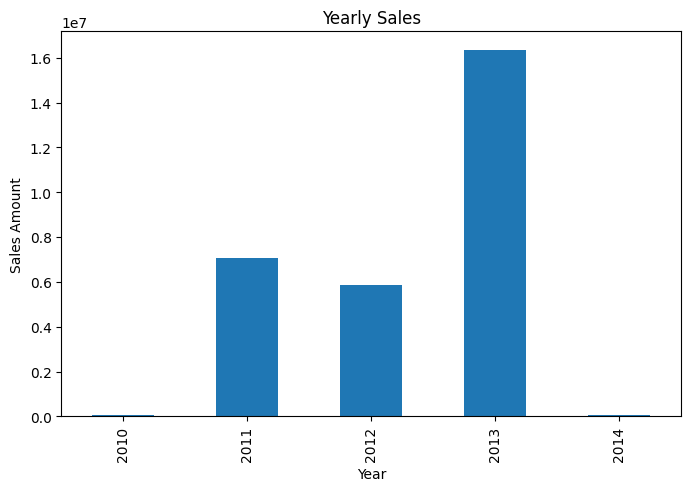

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
yearly_sales.plot(kind='bar', ax=ax)
plt.xlabel('Year')
plt.ylabel('Sales Amount')
plt.title('Yearly Sales')
plt.show()

In [6]:
fig.savefig('yearly_sales.pdf', format='pdf', bbox_inches='tight')
plt.show()

In [7]:
from google.colab import files
files.download("yearly_sales.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>